# Computing the relative error between the two models

This notebook demonstrates the accuracy and flexibility of the TMSE-BioCRNpyler modules by comparing our simulated outputs to the transcription-factor-based biosensors published in Programming Cell-free Biosensors with DNA Strand Displacement Circuits ([Jung et al. *Nature Chemical Biology* 2022](https://www.nature.com/articles/s41589-021-00962-9)).

The notebook then generates comparative plots for multiple species side-by-side and calculates the bidirectional relative error, alternating which model serves as the 'true' baseline.

## Global variables, definitions, and dependencies

In [1]:
import pylab as plt
import pandas as pd
import numpy as np
from pathlib import Path

# Get base directory for BioCRNpyler scripts
directory = Path.cwd()
for p in [directory, *directory.parents]:
    if p.name == 'TMSE_BioCRNpyler_Library':
        base_dir = p
        break

# Directory for Figures and Data
figs_dir = (base_dir / 'figures').as_posix()
data_dir = (base_dir / 'data').as_posix()

# Simulate all models - example for 2 hours
timepoints = np.linspace(0,2,5001)*3600

line_colors = [[0,0,1],
               [0,0.8,1]]

font = 'MS Reference Sans Serif'
plt.rcParams["svg.fonttype"] = "none"
plt.rcParams['font.sans-serif'] = ['MS Reference Sans Serif']

## Plotting simulation results and relative error for Signal

In [2]:
# Dictionary map of species to compare between models
species2compare= {'SD':'dna_Signal_green'}

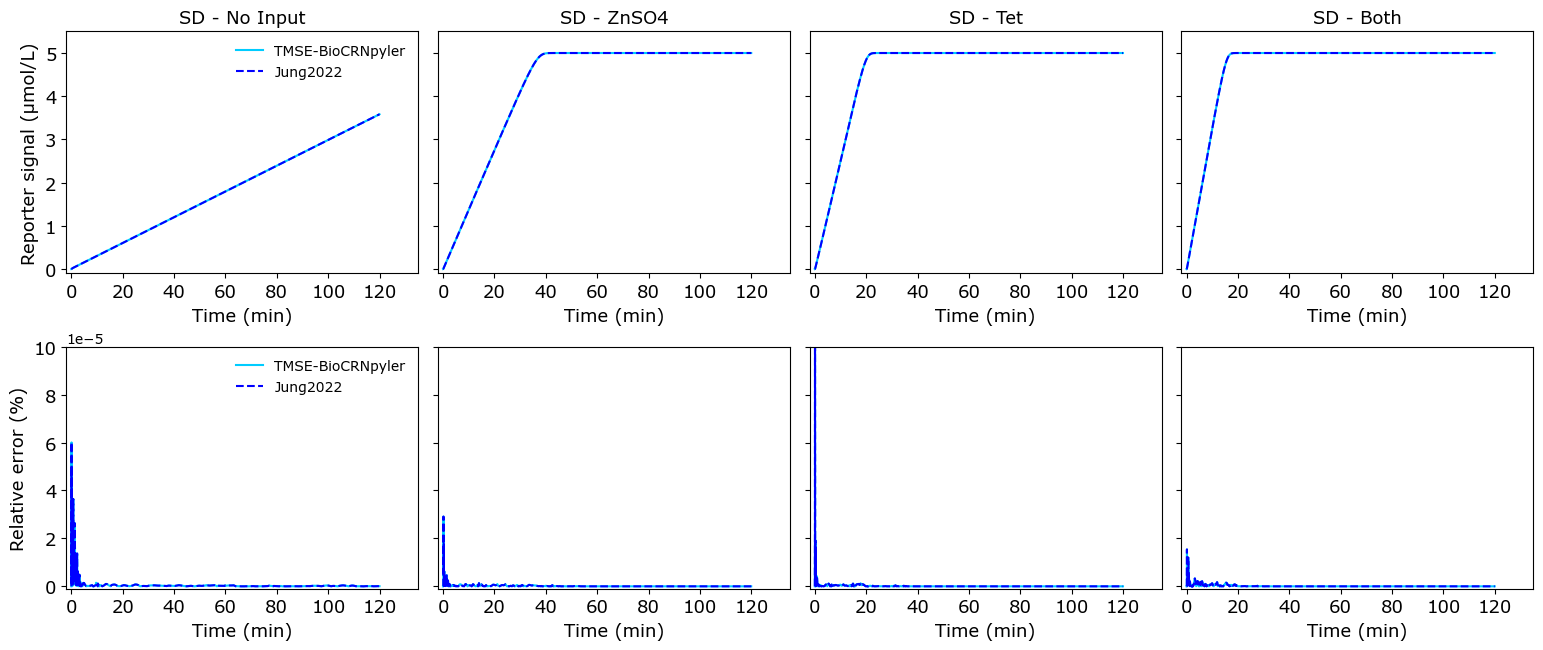

In [3]:
indiv_figW = 19.25 # figure width
indiv_figH = 9.25 # figure height
fs = 13
# Simulation plots
plt.figure(figsize=(indiv_figW, indiv_figH))

Notsim_error = pd.DataFrame()
BioCRNpyler_error = pd.DataFrame()
cnt = 1

for key in ['No Input', 'ZnSO4', 'Tet','Both']:
    # Data for the current condition
    Notsim_df = pd.read_csv(f'{data_dir}/validation_Jung2022_OR_{key}.csv')
    BioCRNpyler_df = pd.read_csv(f'{data_dir}/validation_Jung2022_OR_BioCRNpyler_{key}.csv')

    for col_var in species2compare.keys():
        crn_species = species2compare[col_var]
        
        plt.subplot(3,5,cnt)
        plt.title(f"{col_var} - {key}",fontsize=fs)
        
        plt.plot(timepoints/60, BioCRNpyler_df[crn_species], color=line_colors[1])
        plt.plot(timepoints/60, Notsim_df[col_var], color=line_colors[0], linestyle='dashed')
        
        
        # Format the plot
        plt.ylim(-0.1, 5.5)
        plt.xlim(-2,135)
        plt.xlabel('Time (min)',fontsize=fs)
        plt.xticks(fontsize=fs)
        plt.yticks(fontsize=fs)
        if cnt == 1 or cnt == 6: 
            plt.ylabel('Reporter signal (μmol/L)',fontsize=fs)
            plt.legend(['TMSE-BioCRNpyler','Jung2022'],frameon=False)
        else:
            ax1 = plt.gca()
            ax1.yaxis.set_ticklabels([])

        # Calculate error
        delta_diff = np.abs(BioCRNpyler_df[crn_species] - Notsim_df[col_var])
        Notsim_error[col_var] = 100 * delta_diff / BioCRNpyler_df[crn_species]
        BioCRNpyler_error[col_var] = 100 * delta_diff / Notsim_df[col_var]

        # Error plots
        plt.subplot(3,5,5+cnt)
        plt.plot(timepoints/60, BioCRNpyler_error[col_var], color=line_colors[1])
        plt.plot(timepoints/60, Notsim_error[col_var], color=line_colors[0], linestyle='dashed')
        # Format the plot
        plt.ylim(-10e-7, 10e-5)
        plt.xlim(-2,135)
        plt.xlabel('Time (min)',fontsize=fs)
        plt.xticks(fontsize=fs)
        plt.yticks(fontsize=fs)
        if cnt == 1 or cnt == 6: 
            plt.ylabel('Relative error (%)',fontsize=fs)
            plt.legend(['TMSE-BioCRNpyler','Jung2022'],frameon=False)
        else:
            ax1 = plt.gca()
            ax1.yaxis.set_ticklabels([])
        
        cnt+=1     

plt.tight_layout(h_pad=0.5) 
plt.savefig(f"{figs_dir}/validation_JungOR22_{key}_{col_var}_combined.svg", format='svg')

## Comparing against using DNA assembly and Hill propensity (No RNAP)

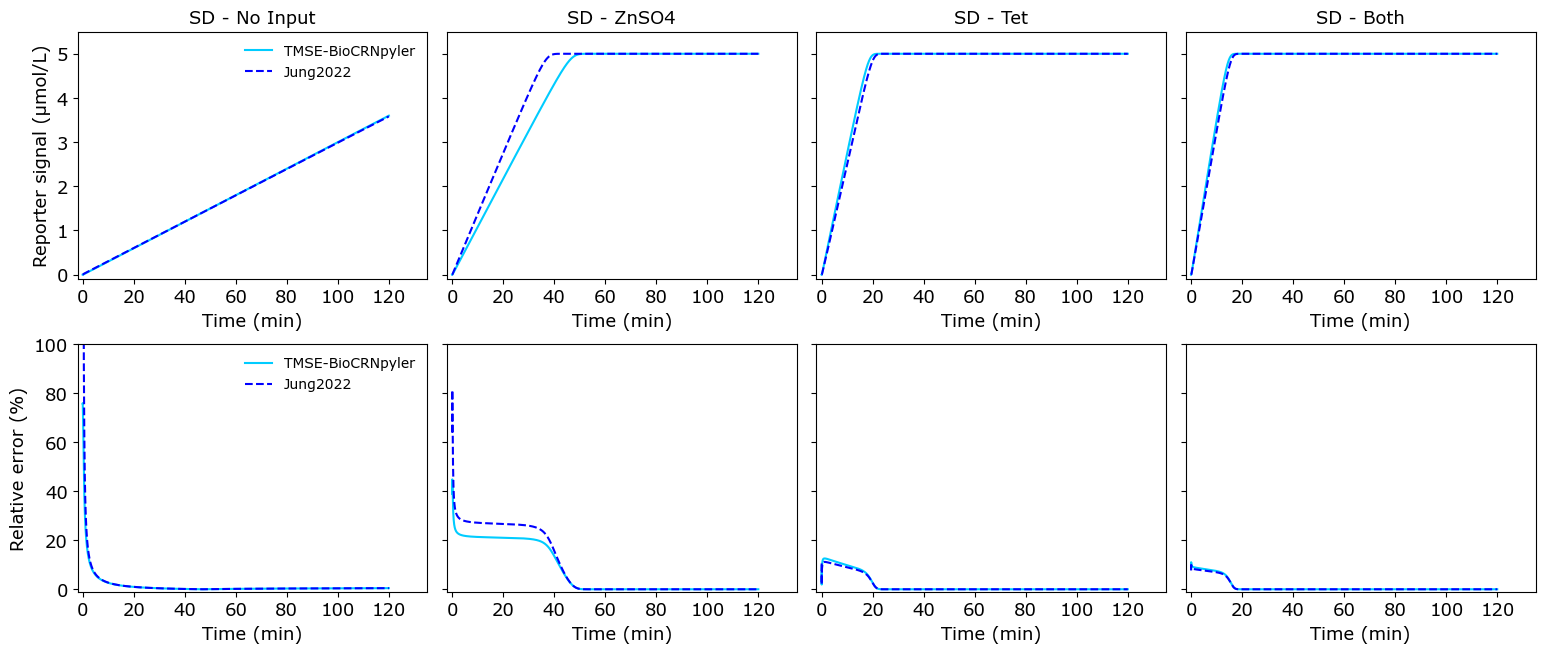

In [4]:
species2compare= {'SD':'dna_Signal_2'}

indiv_figW = 19.25 # figure width
indiv_figH = 9.25 # figure height
fs = 13
# Simulation plots
plt.figure(figsize=(indiv_figW, indiv_figH))

Notsim_error = pd.DataFrame()
BioCRNpyler_error = pd.DataFrame()
cnt = 1

for key in ['No Input', 'ZnSO4', 'Tet','Both']:
    # Data for the current condition
    Notsim_df = pd.read_csv(f'{data_dir}/validation_Jung2022_OR_{key}.csv')
    BioCRNpyler_df = pd.read_csv(f'{data_dir}/validation_Jung2022_OR_BioCRNpylerHill_{key}.csv')

    for col_var in species2compare.keys():
        crn_species = species2compare[col_var]
        
        plt.subplot(3,5,cnt)
        plt.title(f"{col_var} - {key}",fontsize=fs)
        
        plt.plot(timepoints/60, BioCRNpyler_df[crn_species], color=line_colors[1])
        plt.plot(timepoints/60, Notsim_df[col_var], color=line_colors[0], linestyle='dashed')
        
        
        # Format the plot
        plt.ylim(-0.1, 5.5)
        plt.xlim(-2,135)
        plt.xlabel('Time (min)',fontsize=fs)
        plt.xticks(fontsize=fs)
        plt.yticks(fontsize=fs)
        if cnt == 1 or cnt == 6: 
            plt.ylabel('Reporter signal (μmol/L)',fontsize=fs)
            plt.legend(['TMSE-BioCRNpyler','Jung2022'],frameon=False)
        else:
            ax1 = plt.gca()
            ax1.yaxis.set_ticklabels([])

        # Calculate error
        delta_diff = np.abs(BioCRNpyler_df[crn_species] - Notsim_df[col_var])
        Notsim_error[col_var] = 100 * delta_diff / BioCRNpyler_df[crn_species]
        BioCRNpyler_error[col_var] = 100 * delta_diff / Notsim_df[col_var]

        # Error plots
        plt.subplot(3,5,5+cnt)
        plt.plot(timepoints/60, BioCRNpyler_error[col_var], color=line_colors[1])
        plt.plot(timepoints/60, Notsim_error[col_var], color=line_colors[0], linestyle='dashed')
        # Format the plot
        plt.ylim(-1, 100)
        plt.xlim(-2,135)
        plt.xlabel('Time (min)',fontsize=fs)
        plt.xticks(fontsize=fs)
        plt.yticks(fontsize=fs)
        if cnt == 1 or cnt == 6: 
            plt.ylabel('Relative error (%)',fontsize=fs)
            plt.legend(['TMSE-BioCRNpyler','Jung2022'],frameon=False)
        else:
            ax1 = plt.gca()
            ax1.yaxis.set_ticklabels([])
        
        cnt+=1 

plt.tight_layout(h_pad=0.5) 
plt.savefig(f"{figs_dir}/validation_JungOR22_{key}_{col_var}_Hillcombined.svg", format='svg')

# Computing environment

In [5]:
%load_ext watermark
%watermark -v -p bioscrape,bokeh,jupyterlab,biocrnpyler

Python implementation: CPython
Python version       : 3.12.12
IPython version      : 9.12.0

bioscrape  : 1.2.1
bokeh      : 3.9.1
jupyterlab : 4.5.0
biocrnpyler: 1.3.2

